In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression


In [2]:
# === LOAD IMAGES ===

stationary_img_path = r"C:\Users\murat\Downloads\THERMAL CROPPED IRX.JPG"
drone_img_path      = r"C:\Users\murat\Downloads\DRONE CROPPED IRX_3353.JPG"

# Read (OpenCV loads in BGR)
stationary_bgr = cv2.imread(stationary_img_path)
drone_bgr      = cv2.imread(drone_img_path)

if stationary_bgr is None:
    raise FileNotFoundError("Stationary image path is incorrect.")

if drone_bgr is None:
    raise FileNotFoundError("Drone image path is incorrect.")

# Convert to RGB
stationary_rgb = cv2.cvtColor(stationary_bgr, cv2.COLOR_BGR2RGB)
drone_rgb      = cv2.cvtColor(drone_bgr, cv2.COLOR_BGR2RGB)

# Convert to grayscale
stationary_gray = cv2.cvtColor(stationary_rgb, cv2.COLOR_RGB2GRAY)
drone_gray      = cv2.cvtColor(drone_rgb, cv2.COLOR_RGB2GRAY)

print("Images successfully loaded and converted.")


Images successfully loaded and converted.


In [3]:
# === Resize drone to match stationary image dimensions ===
drone_gray_resized = cv2.resize(drone_gray, (stationary_gray.shape[1], stationary_gray.shape[0]))

drone_gray = drone_gray_resized.copy()

print("Resizing complete:", stationary_gray.shape, drone_gray.shape)


Resizing complete: (217, 385) (217, 385)


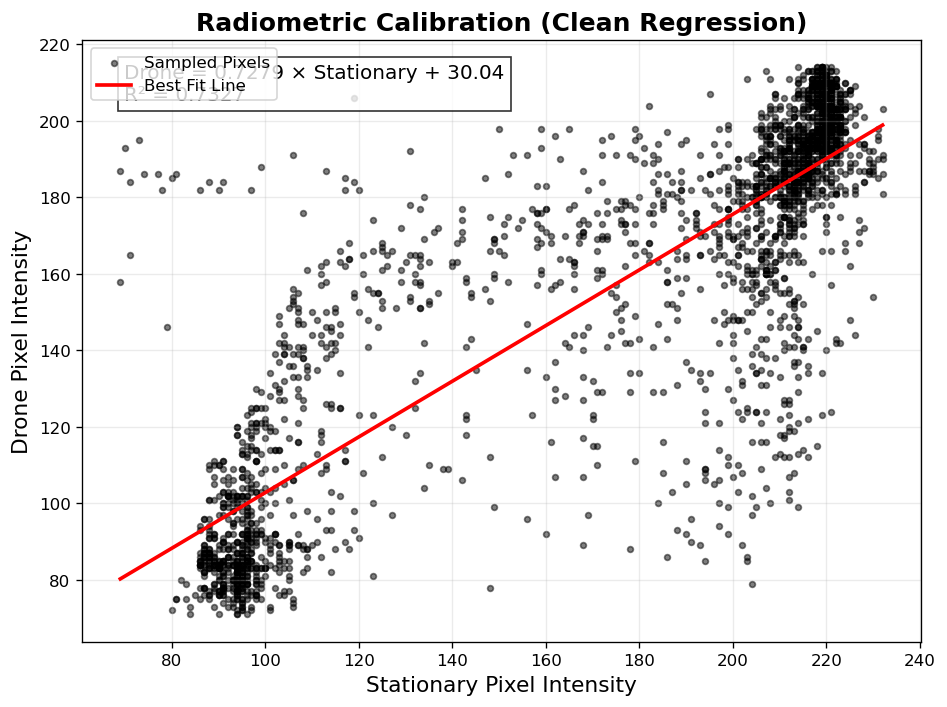

In [4]:
# ===========================================================
# CLEAN SCIENTIFIC REGRESSION FOR DRONE VS STATIONARY
# ===========================================================

# --- 1. Crop to center region (middle 40% of each image) ---
h, w = stationary_gray.shape
crop = np.s_[int(h*0.3):int(h*0.7), int(w*0.3):int(w*0.7)]

stationary_crop = stationary_gray[crop]
drone_crop      = drone_gray[crop]

# Flatten
X_vals = stationary_crop.flatten().astype(float)
Y_vals = drone_crop.flatten().astype(float)

# --- 2. Remove extreme pixel outliers (1% tail trim) ---
low_x, high_x = np.percentile(X_vals, [1, 99])
low_y, high_y = np.percentile(Y_vals, [1, 99])

mask = (
    (X_vals > low_x) & (X_vals < high_x) &
    (Y_vals > low_y) & (Y_vals < high_y)
)

X_clean = X_vals[mask]
Y_clean = Y_vals[mask]

# --- 3. Sample fixed number of points for clean plot ---
N = 2500
idx = np.random.choice(len(X_clean), size=N, replace=False)
X_plot = X_clean[idx]
Y_plot = Y_clean[idx]

# --- 4. Fit regression ---
model = LinearRegression().fit(X_clean.reshape(-1,1), Y_clean)
a = float(model.coef_[0])
b = float(model.intercept_)
r2 = model.score(X_clean.reshape(-1,1), Y_clean)

# --- 5. Make CLEAN PUBLICATION-QUALITY REGRESSION PLOT ---
plt.figure(figsize=(8,6), dpi=120)

plt.scatter(X_plot, Y_plot, s=12, alpha=0.5, color="black", label="Sampled Pixels")

x_line = np.linspace(min(X_plot), max(X_plot), 300)
y_line = a * x_line + b
plt.plot(x_line, y_line, color="red", linewidth=2.2, label="Best Fit Line")

plt.title("Radiometric Calibration (Clean Regression)", fontsize=15, weight='bold')
plt.xlabel("Stationary Pixel Intensity", fontsize=13)
plt.ylabel("Drone Pixel Intensity", fontsize=13)

plt.text(
    0.05, 0.9,
    f"Drone = {a:.4f} × Stationary + {b:.2f}\nR² = {r2:.4f}",
    transform=plt.gca().transAxes,
    fontsize=12,
    bbox=dict(facecolor="white", edgecolor="black", alpha=0.8)
)

plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()


In [6]:
import cv2
import numpy as np

# --------------------------------------------
# 1. Load images
# --------------------------------------------
stationary_img_path = r"C:\Users\murat\Downloads\THERMAL CROPPED IRX.JPG"
drone_img_path     = r"C:\Users\murat\Downloads\DRONE CROPPED IRX_3353.JPG"

stationary_rgb = cv2.imread(stationary_img_path)
drone_rgb      = cv2.imread(drone_img_path)

stationary_rgb = cv2.cvtColor(stationary_rgb, cv2.COLOR_BGR2RGB)
drone_rgb      = cv2.cvtColor(drone_rgb, cv2.COLOR_BGR2RGB)

# Convert to grayscale
stationary_gray = cv2.cvtColor(stationary_rgb, cv2.COLOR_RGB2GRAY)
drone_gray      = cv2.cvtColor(drone_rgb, cv2.COLOR_RGB2GRAY)

# --------------------------------------------
# 2. Crop central region (middle 40% of both)
# --------------------------------------------
h, w = stationary_gray.shape
crop = np.s_[int(h*0.3):int(h*0.7), int(w*0.3):int(w*0.7)]

stationary_crop = stationary_gray[crop]
drone_crop      = drone_gray[crop]

# --------------------------------------------
# 3. Flatten images
# --------------------------------------------
stat_flat = stationary_crop.flatten()
drone_flat = drone_crop.flatten()

# --------------------------------------------
# 4. Remove invalid pixels
# --------------------------------------------
mask = (stat_flat > 0) & (drone_flat > 0)
stat_valid = stat_flat[mask]
drone_valid = drone_flat[mask]

# --------------------------------------------
# 5. Sample matched pixel pairs
# --------------------------------------------
N = min(7000, len(stat_valid))
idx = np.random.choice(len(stat_valid), N, replace=False)

stationary_sample = stat_valid[idx]
drone_sample      = drone_valid[idx]

print("Sampling complete:")
print("Stationary sample size:", len(stationary_sample))
print("Drone sample size:", len(drone_sample))


Sampling complete:
Stationary sample size: 7000
Drone sample size: 7000


=== Polynomial Regression Results ===
Degree 1:  R² = 0.056,   RMSE = 28.91
Degree 2:  R² = 0.059,   RMSE = 28.87
Degree 3:  R² = 0.059,   RMSE = 28.87

>>> BEST MODEL: Degree 3
R² = 0.059,  RMSE = 28.87


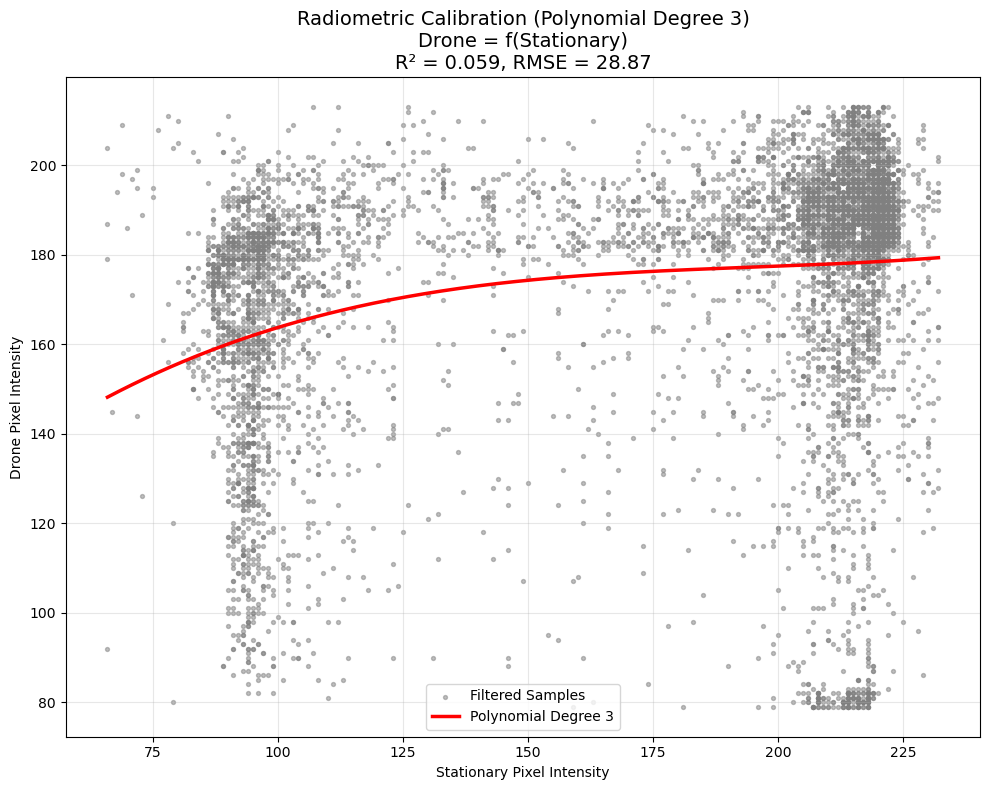

In [7]:
# ================================================
# Polynomial Regression for Radiometric Calibration
# Drone = f(Stationary)
# ================================================
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

# Use previously cleaned + sampled data
X = stationary_sample.reshape(-1, 1)   # input
Y = drone_sample.reshape(-1, 1)        # output

# ---- Remove extreme outliers (top/bottom 1%) ----
low_x, high_x = np.percentile(X, [1, 99])
low_y, high_y = np.percentile(Y, [1, 99])
mask = (X >= low_x) & (X <= high_x) & (Y >= low_y) & (Y <= high_y)

X_f = X[mask].reshape(-1, 1)
Y_f = Y[mask].reshape(-1, 1)

# ---- Fit polynomial models ----
degrees = [1, 2, 3]  # linear, quadratic, cubic
models = {}

print("=== Polynomial Regression Results ===")
for d in degrees:
    poly = PolynomialFeatures(degree=d)
    X_poly = poly.fit_transform(X_f)
    
    model = LinearRegression().fit(X_poly, Y_f)
    Y_pred = model.predict(X_poly)

    r2 = r2_score(Y_f, Y_pred)
    rmse = np.sqrt(mean_squared_error(Y_f, Y_pred))

    models[d] = (poly, model, r2, rmse)

    print(f"Degree {d}:  R² = {r2:.3f},   RMSE = {rmse:.2f}")

# ---- Select best model (highest R²) ----
best_degree = max(models, key=lambda d: models[d][2])
poly_best, model_best, r2_best, rmse_best = models[best_degree]

print("\n>>> BEST MODEL: Degree", best_degree)
print(f"R² = {r2_best:.3f},  RMSE = {rmse_best:.2f}")

# ---- Plot the result ----
plt.figure(figsize=(10, 8))
plt.scatter(X_f, Y_f, s=8, color='gray', alpha=0.5, label='Filtered Samples')

# Regression curve
x_curve = np.linspace(X_f.min(), X_f.max(), 400).reshape(-1, 1)
x_curve_poly = poly_best.transform(x_curve)
y_curve = model_best.predict(x_curve_poly)

plt.plot(x_curve, y_curve, color='red', linewidth=2.5, label=f'Polynomial Degree {best_degree}')

# --- Labels & title ---
plt.title(f"Radiometric Calibration (Polynomial Degree {best_degree})\n"
          f"Drone = f(Stationary)\n"
          f"R² = {r2_best:.3f}, RMSE = {rmse_best:.2f}",
          fontsize=14)

plt.xlabel("Stationary Pixel Intensity")
plt.ylabel("Drone Pixel Intensity")

plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

